In [2]:

# ============================================
# CREDIT RISK ML SYSTEM
# Phase 1: Data Understanding
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully!
Pandas version: 3.0.2
NumPy version: 2.4.4


In [4]:

import pandas as pd
from pathlib import Path

# Original dataset location
DATA_PATH = Path(
    r"D:\DOWNLOAD\Credit-Risk-Assesment-using-SHAP-main\Credit-Risk-Assesment-using-SHAP-main\credit_risk_dataset.csv"
)

# Verify that the file exists
print("Dataset file exists:", DATA_PATH.exists())

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)

    print("\nDataset loaded successfully!")
    print("Dataset shape:", df.shape)

    display(df.head())
else:
    print("File not found. Please verify the path.")


Dataset file exists: True

Dataset loaded successfully!
Dataset shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [5]:

# ============================================
# PHASE 1: DATA QUALITY CHECK
# ============================================

print("Dataset Shape:", df.shape)

print("\n--- Column Names ---")
print(df.columns.tolist())

print("\n--- Data Types ---")
display(df.dtypes.to_frame(name="Data Type"))

print("\n--- Missing Values ---")
missing = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

display(
    missing_report
    .sort_values("Missing Values", ascending=False)
)

print("\n--- Duplicate Rows ---")
print("Duplicate count:", df.duplicated().sum())

print("\n--- Target Distribution ---")
display(df["loan_status"].value_counts().to_frame("Count"))

print("\n--- Target Distribution Percentage ---")
display(
    (df["loan_status"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)


Dataset Shape: (32581, 12)

--- Column Names ---
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

--- Data Types ---


,Data Type
person_age,int64
person_income,int64
person_home_ownership,str
person_emp_length,float64
loan_intent,str
loan_grade,str
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64



--- Missing Values ---


,Missing Values,Missing Percentage
loan_int_rate,3116,9.56
person_emp_length,895,2.75
person_income,0,0.00
person_age,0,0.00
person_home_ownership,0,0.00
loan_intent,0,0.00
loan_grade,0,0.00
loan_amnt,0,0.00
loan_status,0,0.00
loan_percent_income,0,0.00



--- Duplicate Rows ---
Duplicate count: 165

--- Target Distribution ---


,Count
loan_status,
0,25473
1,7108



--- Target Distribution Percentage ---


,Percentage
loan_status,
0,78.18
1,21.82


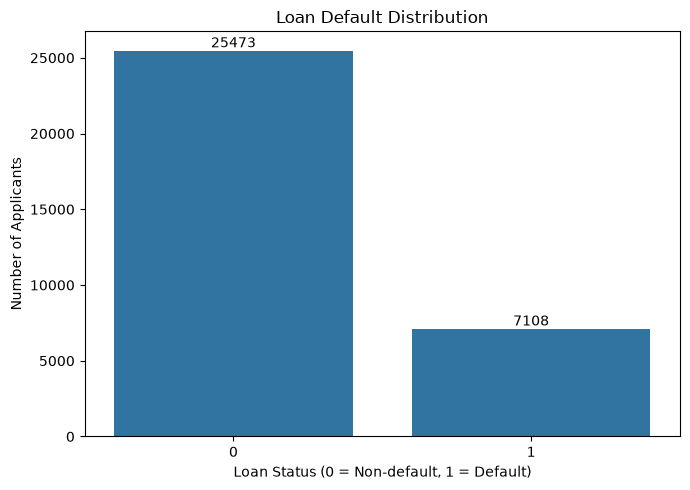

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="loan_status"
)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status (0 = Non-default, 1 = Default)")
plt.ylabel("Number of Applicants")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()


In [7]:

numeric_cols = df.select_dtypes(include=np.number).columns

display(df[numeric_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [8]:

# ============================================
# PHASE 1: OUTLIER AND DATA QUALITY AUDIT
# ============================================

# 1. Check unusual ages and employment lengths
print("--- Suspicious Age Values ---")
display(
    df.loc[
        (df["person_age"] < 18) |
        (df["person_age"] > 100),
        ["person_age", "person_income", "loan_status"]
    ].head(20)
)

print("\n--- Suspicious Employment Lengths ---")
display(
    df.loc[
        (df["person_emp_length"] < 0) |
        (df["person_emp_length"] > df["person_age"]),
        ["person_age", "person_emp_length", "loan_status"]
    ].head(20)
)

# 2. Count suspicious records
print("\nAge above 100:", (df["person_age"] > 100).sum())

print(
    "Employment length greater than age:",
    (df["person_emp_length"] > df["person_age"]).sum()
)

print(
    "Negative employment length:",
    (df["person_emp_length"] < 0).sum()
)

# 3. Inspect exact duplicate records
duplicates = df[df.duplicated(keep=False)].sort_values(
    by=df.columns.tolist()
)

print("\nRows participating in exact duplicates:", len(duplicates))
display(duplicates.head(10))

# 4. Compare numeric features by target
print("\n--- Numeric Feature Means by Loan Status ---")
display(
    df.groupby("loan_status")[
        ["person_age", "person_income", "person_emp_length",
         "loan_amnt", "loan_int_rate", "loan_percent_income"]
    ].mean().T
)


--- Suspicious Age Values ---


,person_age,person_income,loan_status
81,144,250000,0
183,144,200000,0
575,123,80004,0
747,123,78000,0
32297,144,6000000,0



--- Suspicious Employment Lengths ---


,person_age,person_emp_length,loan_status
0,22,123.0,1
210,21,123.0,0



Age above 100: 5
Employment length greater than age: 2
Negative employment length: 0

Rows participating in exact duplicates: 330


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3



--- Numeric Feature Means by Loan Status ---


loan_status,0,1
person_age,27.807129,27.474676
person_income,70804.361559,49125.652223
person_emp_length,4.968745,4.137562
loan_amnt,9237.464178,10850.502954
loan_int_rate,10.435999,13.060207
loan_percent_income,0.148805,0.246889


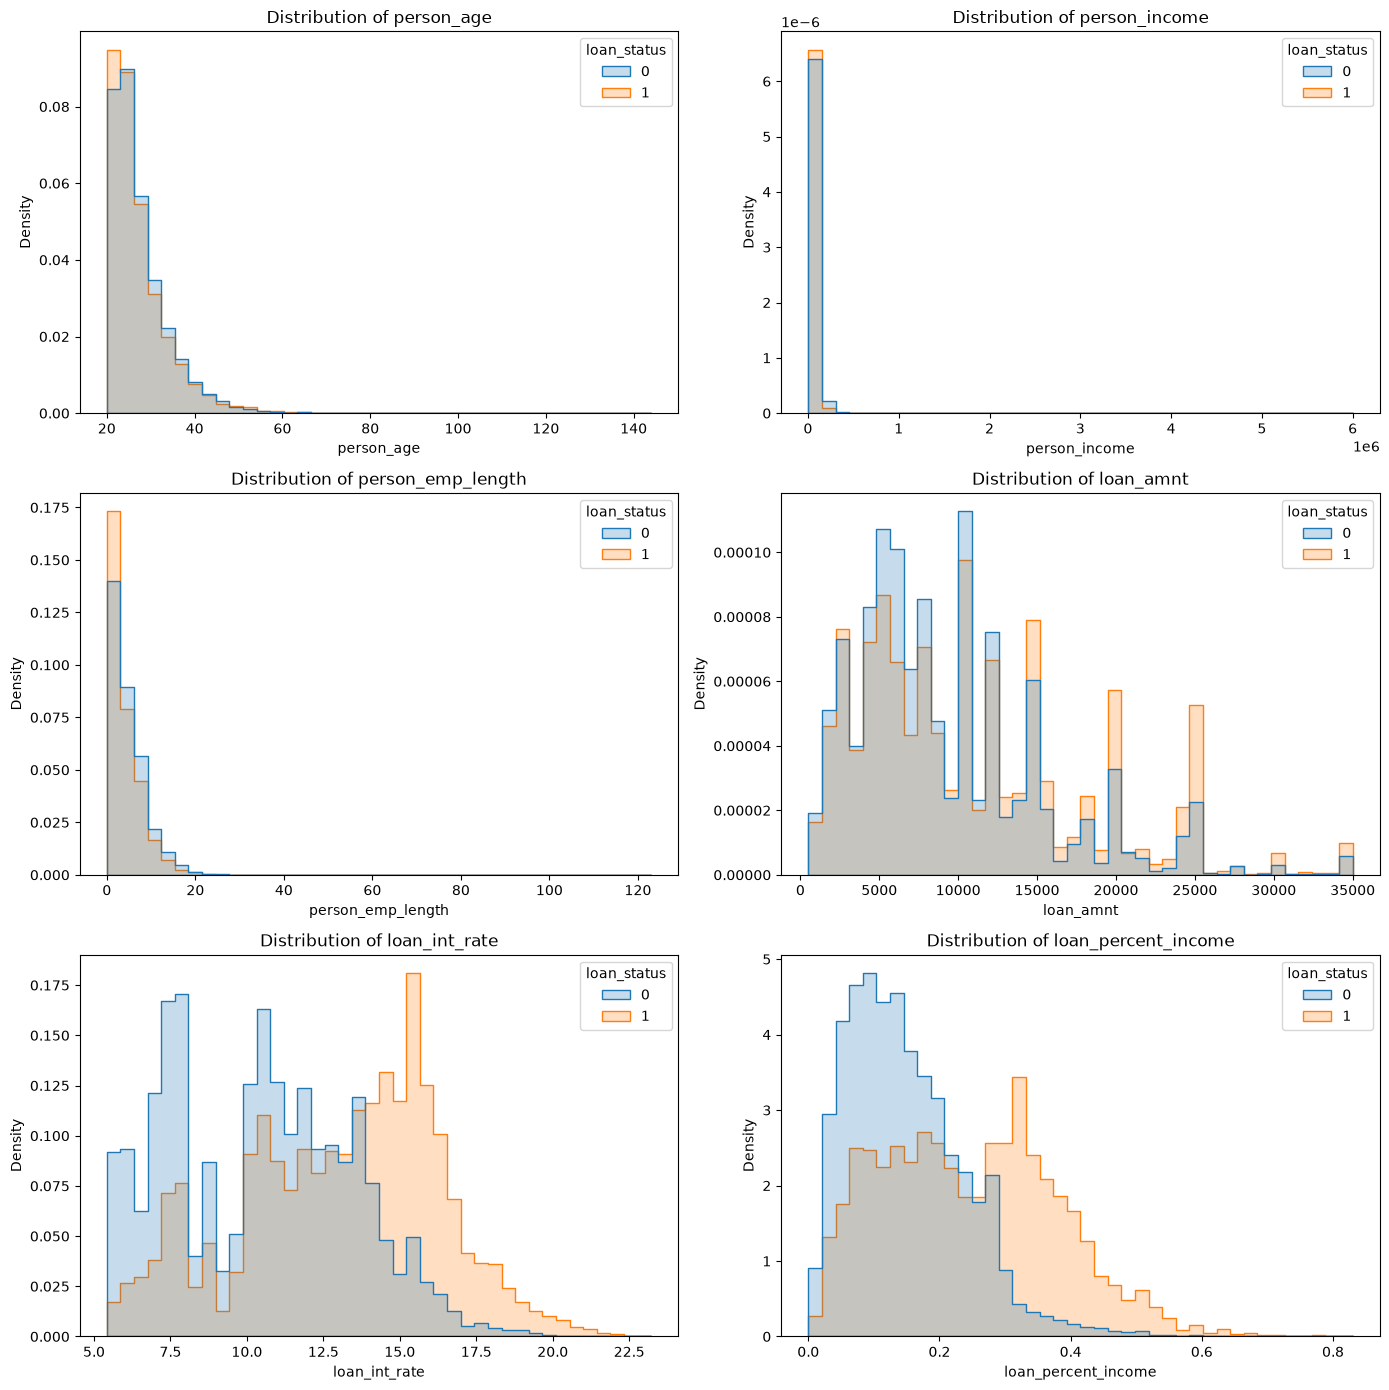

In [9]:

# Plot important numerical features
features = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    sns.histplot(
        data=df,
        x=feature,
        hue="loan_status",
        bins=40,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()


In [10]:

# ============================================
# PHASE 1: FINAL DATA QUALITY AUDIT
# ============================================

# 1. Count duplicate groups and excess rows
print("--- Duplicate Audit ---")

duplicate_mask = df.duplicated(keep=False)
print("Rows in duplicate groups:", duplicate_mask.sum())
print("Excess rows removable:", df.duplicated().sum())

# 2. Check whether identical features have conflicting targets
feature_cols = [
    col for col in df.columns
    if col != "loan_status"
]

label_conflicts = (
    df.groupby(feature_cols, dropna=False)["loan_status"]
    .nunique()
)

print(
    "Feature-identical groups with conflicting labels:",
    (label_conflicts > 1).sum()
)

# 3. Investigate employment length sentinel
print("\n--- Employment Length = 123 ---")

display(
    df.loc[
        df["person_emp_length"] == 123,
        [
            "person_age",
            "person_income",
            "person_emp_length",
            "loan_status"
        ]
    ]
)

# 4. Count unusual values
print("\n--- Anomaly Counts ---")
print("Age > 100:", (df["person_age"] > 100).sum())
print("Age < 18:", (df["person_age"] < 18).sum())

print(
    "Employment length > age:",
    (df["person_emp_length"] > df["person_age"]).sum()
)

print(
    "Employment length = 123:",
    (df["person_emp_length"] == 123).sum()
)


--- Duplicate Audit ---
Rows in duplicate groups: 330
Excess rows removable: 165
Feature-identical groups with conflicting labels: 0

--- Employment Length = 123 ---


,person_age,person_income,person_emp_length,loan_status
0,22,59000,123.0,1
210,21,192000,123.0,0



--- Anomaly Counts ---
Age > 100: 5
Age < 18: 0
Employment length > age: 2
Employment length = 123: 2


In [11]:

# ============================================
# PHASE 1: DATA CLEANING
# ============================================

# Preserve the original dataset
df_clean = df.copy()

print("Original shape:", df.shape)

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

print("After removing duplicates:", df_clean.shape)

# 2. Handle suspicious employment lengths
# 123 years is not a plausible employment duration here.
invalid_emp = (
    (df_clean["person_emp_length"] > df_clean["person_age"]) |
    (df_clean["person_emp_length"] < 0)
)

print("Invalid employment values:", invalid_emp.sum())

df_clean.loc[invalid_emp, "person_emp_length"] = np.nan

# 3. Flag implausible ages for investigation
# Do not delete records; mark these values as missing.
invalid_age = df_clean["person_age"] > 100

print("Implausible ages:", invalid_age.sum())

df_clean.loc[invalid_age, "person_age"] = np.nan

# 4. Review the cleaning results
print("\n--- Cleaning Summary ---")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

print("\n--- Missing Values After Cleaning ---")
display(
    df_clean.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("\n--- Target Distribution After Cleaning ---")
display(
    df_clean["loan_status"]
    .value_counts()
    .sort_index()
    .to_frame("Count")
)

print("\nCleaned dataset created successfully!")


Original shape: (32581, 12)
After removing duplicates: (32416, 12)
Invalid employment values: 2
Implausible ages: 5

--- Cleaning Summary ---
Original rows: 32581
Cleaned rows: 32416
Rows removed: 165

--- Missing Values After Cleaning ---


,Missing Values
loan_int_rate,3095
person_emp_length,889
person_age,5
person_income,0
person_home_ownership,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0



--- Target Distribution After Cleaning ---


,Count
loan_status,
0,25327
1,7089



Cleaned dataset created successfully!


In [12]:

# ============================================
# PHASE 2: TRAIN / VALIDATION / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=["loan_status"]).copy()
y = df_clean["loan_status"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(
    y.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)


Features shape: (32416, 11)
Target shape: (32416,)

Target distribution:


,Percentage
loan_status,
0,78.13
1,21.87


In [13]:

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nTarget percentages in each split:")

for name, target in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}:")
    print((target.value_counts(normalize=True) * 100).round(2))


Training set: (22691, 11) (22691,)
Validation set: (4862, 11) (4862,)
Test set: (4863, 11) (4863,)

Target percentages in each split:

Train:
loan_status
0    78.13
1    21.87
Name: proportion, dtype: float64

Validation:
loan_status
0    78.14
1    21.86
Name: proportion, dtype: float64

Test:
loan_status
0    78.12
1    21.88
Name: proportion, dtype: float64


In [14]:

# Check sizes and missing values
assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty

assert "loan_status" not in X_train.columns

print("All split checks passed!")
print("No overlapping row indices between splits.")
print("Target column is excluded from features.")


All split checks passed!
No overlapping row indices between splits.
Target column is excluded from features.


In [15]:

# ============================================
# PHASE 3: FEATURE PREPROCESSING
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Identify columns using training data only
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


Numerical features: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Categorical features: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [16]:

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [17]:

# ============================================
# BASELINE MODEL
# ============================================

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Fit ONLY on training data
baseline_model.fit(X_train, y_train)

print("Logistic Regression training completed!")


Logistic Regression training completed!


VALIDATION RESULTS
----------------------------------------
ROC-AUC: 0.8668
PR-AUC:  0.7214

Classification Report:
                 precision    recall  f1-score   support

Non-default (0)       0.89      0.95      0.92      3799
    Default (1)       0.77      0.56      0.65      1063

       accuracy                           0.87      4862
      macro avg       0.83      0.76      0.78      4862
   weighted avg       0.86      0.87      0.86      4862

Confusion Matrix:


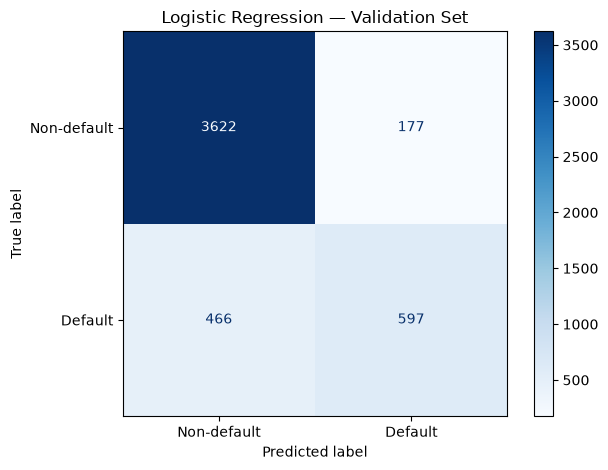

In [18]:

# Predict on validation set
val_probabilities = baseline_model.predict_proba(X_val)[:, 1]
val_predictions = (val_probabilities >= 0.5).astype(int)

# Calculate metrics
val_roc_auc = roc_auc_score(y_val, val_probabilities)
val_pr_auc = average_precision_score(y_val, val_probabilities)

print("VALIDATION RESULTS")
print("-" * 40)
print(f"ROC-AUC: {val_roc_auc:.4f}")
print(f"PR-AUC:  {val_pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    target_names=["Non-default (0)", "Default (1)"],
    zero_division=0
))

print("Confusion Matrix:")
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    display_labels=["Non-default", "Default"],
    cmap="Blues"
)
plt.title("Logistic Regression — Validation Set")
plt.tight_layout()
plt.show()


In [19]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)


,threshold,precision,recall,f1_score,true_positives,false_positives,false_negatives,true_negatives
0,0.20,0.5257,0.7789,0.6277,828,747,235,3052
1,0.25,0.5818,0.7460,0.6538,793,570,270,3229
2,0.30,0.6328,0.7150,0.6714,760,441,303,3358
3,0.35,0.6744,0.6820,0.6782,725,350,338,3449
4,0.40,0.7041,0.6425,0.6719,683,287,380,3512
5,0.45,0.7353,0.5983,0.6598,636,229,427,3570
6,0.50,0.7713,0.5616,0.6500,597,177,466,3622
7,0.55,0.7942,0.5155,0.6252,548,142,515,3657
8,0.60,0.8124,0.4685,0.5943,498,115,565,3684


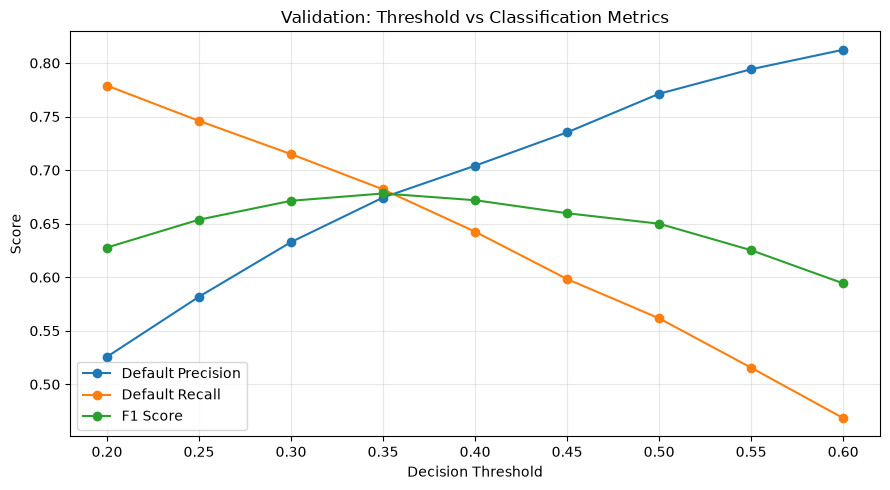

In [20]:

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Default Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Default Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Validation: Threshold vs Classification Metrics")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:

# ============================================
# PHASE 4: RANDOM FOREST MODEL
# ============================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [22]:

# Predict default probabilities
rf_val_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Default threshold for initial comparison
rf_val_predictions = (rf_val_probabilities >= 0.5).astype(int)

rf_roc_auc = roc_auc_score(y_val, rf_val_probabilities)
rf_pr_auc = average_precision_score(y_val, rf_val_probabilities)

print("RANDOM FOREST — VALIDATION RESULTS")
print("-" * 45)
print(f"ROC-AUC: {rf_roc_auc:.4f}")
print(f"PR-AUC:  {rf_pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_val_predictions,
    target_names=["Non-default (0)", "Default (1)"],
    zero_division=0
))


RANDOM FOREST — VALIDATION RESULTS
---------------------------------------------
ROC-AUC: 0.9293
PR-AUC:  0.8798

Classification Report:
                 precision    recall  f1-score   support

Non-default (0)       0.92      0.99      0.96      3799
    Default (1)       0.97      0.71      0.82      1063

       accuracy                           0.93      4862
      macro avg       0.95      0.85      0.89      4862
   weighted avg       0.93      0.93      0.93      4862



In [23]:

# Predict default probabilities
rf_val_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Default threshold for initial comparison
rf_val_predictions = (rf_val_probabilities >= 0.5).astype(int)

rf_roc_auc = roc_auc_score(y_val, rf_val_probabilities)
rf_pr_auc = average_precision_score(y_val, rf_val_probabilities)

print("RANDOM FOREST — VALIDATION RESULTS")
print("-" * 45)
print(f"ROC-AUC: {rf_roc_auc:.4f}")
print(f"PR-AUC:  {rf_pr_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_val_predictions,
    target_names=["Non-default (0)", "Default (1)"],
    zero_division=0
))


RANDOM FOREST — VALIDATION RESULTS
---------------------------------------------
ROC-AUC: 0.9293
PR-AUC:  0.8798

Classification Report:
                 precision    recall  f1-score   support

Non-default (0)       0.92      0.99      0.96      3799
    Default (1)       0.97      0.71      0.82      1063

       accuracy                           0.93      4862
      macro avg       0.95      0.85      0.89      4862
   weighted avg       0.93      0.93      0.93      4862



In [24]:

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": val_roc_auc,
        "PR-AUC": val_pr_auc
    },
    {
        "Model": "Random Forest",
        "ROC-AUC": rf_roc_auc,
        "PR-AUC": rf_pr_auc
    }
]).set_index("Model")

display(model_comparison.round(4))


,ROC-AUC,PR-AUC
Model,,
Logistic Regression,0.8668,0.7214
Random Forest,0.9293,0.8798


In [25]:

# ============================================
# PHASE 4: FEATURE ABLATION EXPERIMENT
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

# Compare four feature configurations
feature_sets = {
    "All features": [],
    "Without loan_grade": ["loan_grade"],
    "Without loan_int_rate": ["loan_int_rate"],
    "Without both": ["loan_grade", "loan_int_rate"]
}

ablation_results = []

for experiment, columns_to_drop in feature_sets.items():

    print(f"Running experiment: {experiment}")

    # Keep the same train/validation rows
    Xtr = X_train.drop(columns=columns_to_drop).copy()
    Xv = X_val.drop(columns=columns_to_drop).copy()

    # Identify column types
    num_cols = Xtr.select_dtypes(
        include=np.number
    ).columns.tolist()

    cat_cols = Xtr.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    # Build preprocessing pipeline
    experiment_preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]),
                num_cols
            ),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore"))
                ]),
                cat_cols
            )
        ]
    )

    # Build and train model
    experiment_model = Pipeline([
        ("preprocessor", experiment_preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    experiment_model.fit(Xtr, y_train)

    # Evaluate on validation data
    probabilities = experiment_model.predict_proba(Xv)[:, 1]

    ablation_results.append({
        "Experiment": experiment,
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

# Display comparison
ablation_df = pd.DataFrame(ablation_results)

ablation_df = ablation_df.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)

print("\nFEATURE ABLATION RESULTS")
display(ablation_df.round(4))


Running experiment: All features
Running experiment: Without loan_grade
Running experiment: Without loan_int_rate
Running experiment: Without both

FEATURE ABLATION RESULTS


,Experiment,ROC-AUC,PR-AUC
0,All features,0.9293,0.8798
1,Without loan_int_rate,0.9250,0.8772
2,Without loan_grade,0.9229,0.8629
3,Without both,0.8756,0.7894


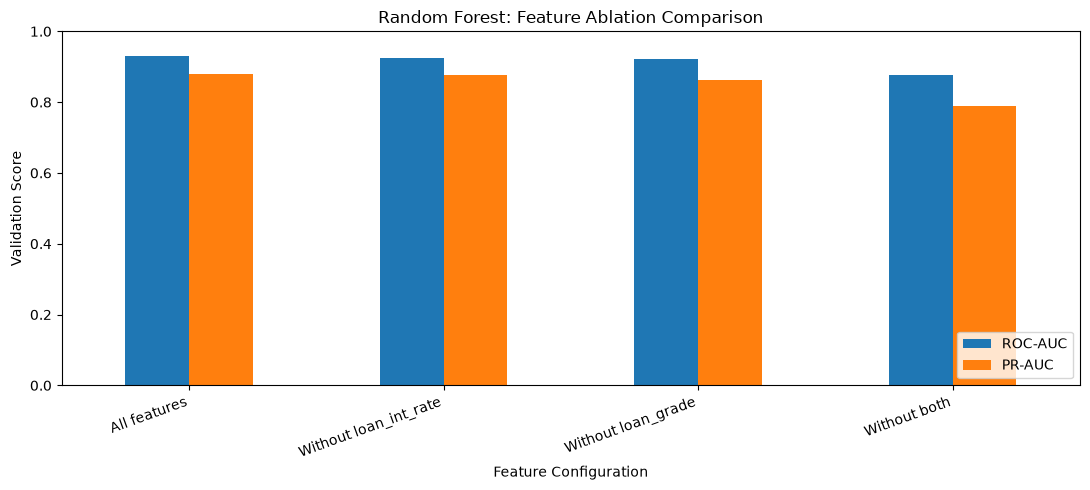

In [26]:

# ============================================
# FEATURE ABLATION VISUALIZATION
# ============================================

ax = ablation_df.set_index("Experiment")[
    ["ROC-AUC", "PR-AUC"]
].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1)
)

ax.set_title("Random Forest: Feature Ablation Comparison")
ax.set_ylabel("Validation Score")
ax.set_xlabel("Feature Configuration")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [27]:

# ============================================
# PHASE 5: PROBABILITY CALIBRATION
# ============================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.base import clone
from sklearn.metrics import brier_score_loss, log_loss

# Calibrate the selected Random Forest pipeline
calibrated_rf = CalibratedClassifierCV(
    estimator=clone(rf_model),
    method="sigmoid",
    cv=3
)

# Fit using training data only
calibrated_rf.fit(X_train, y_train)

print("Calibrated Random Forest trained successfully!")


Calibrated Random Forest trained successfully!


In [28]:

# Generate validation probabilities
raw_probabilities = rf_model.predict_proba(X_val)[:, 1]

calibrated_probabilities = calibrated_rf.predict_proba(X_val)[:, 1]

# Calculate probability quality metrics
calibration_results = pd.DataFrame([
    {
        "Model": "Raw Random Forest",
        "Brier Score": brier_score_loss(y_val, raw_probabilities),
        "Log Loss": log_loss(y_val, raw_probabilities)
    },
    {
        "Model": "Calibrated Random Forest",
        "Brier Score": brier_score_loss(y_val, calibrated_probabilities),
        "Log Loss": log_loss(y_val, calibrated_probabilities)
    }
])

display(calibration_results.round(4))


,Model,Brier Score,Log Loss
0,Raw Random Forest,0.0593,0.2177
1,Calibrated Random Forest,0.0591,0.2172


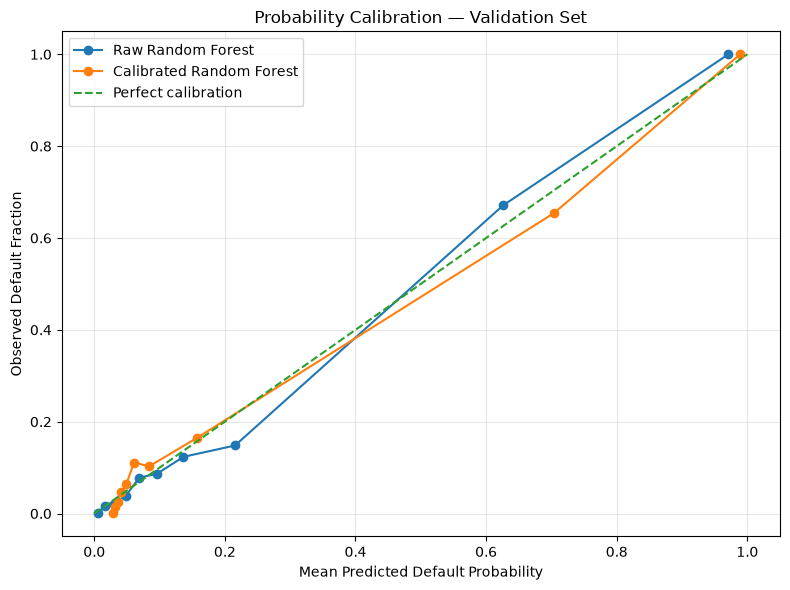

In [29]:

# Compare reliability curves
plt.figure(figsize=(8, 6))

for name, probabilities in [
    ("Raw Random Forest", raw_probabilities),
    ("Calibrated Random Forest", calibrated_probabilities)
]:
    observed_fraction, mean_probability = calibration_curve(
        y_val,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_probability,
        observed_fraction,
        marker="o",
        label=name
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Fraction")
plt.title("Probability Calibration — Validation Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

%pip install shap

  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
# ============================================
# PHASE 6: SHAP EXPLAINABILITY
# ============================================

import shap

# Use a reproducible sample to keep SHAP computation manageable
X_shap_background = X_train.sample(
    n=min(300, len(X_train)),
    random_state=42
)

X_shap_explain = X_val.sample(
    n=min(300, len(X_val)),
    random_state=42
)

# Transform raw inputs using the fitted preprocessing pipeline
fitted_preprocessor = rf_model.named_steps["preprocessor"]

X_background_transformed = fitted_preprocessor.transform(
    X_shap_background
)

X_explain_transformed = fitted_preprocessor.transform(
    X_shap_explain
)

# Convert sparse matrices to dense arrays if necessary
if hasattr(X_background_transformed, "toarray"):
    X_background_transformed = X_background_transformed.toarray()

if hasattr(X_explain_transformed, "toarray"):
    X_explain_transformed = X_explain_transformed.toarray()

# Get feature names after one-hot encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Explain the trained Random Forest
tree_explainer = shap.TreeExplainer(
    rf_model.named_steps["classifier"],
    data=X_background_transformed,
    feature_perturbation="interventional",
    model_output="probability"
)

shap_values = tree_explainer.shap_values(
    X_explain_transformed,
    check_additivity=False
)

print("SHAP values calculated successfully!")
print("Explanation sample shape:", X_explain_transformed.shape)
print("Feature names:", len(feature_names))


c:\Users\Atul Sahu\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.
 99%|===================| 596/600 [02:00<00:00]        

SHAP values calculated successfully!
Explanation sample shape: (300, 26)
Feature names: 26


,Feature,Mean Absolute SHAP
5,num__loan_percent_income,0.0837
1,num__person_income,0.0607
10,cat__person_home_ownership_RENT,0.0406
17,cat__loan_grade_A,0.0292
20,cat__loan_grade_D,0.0266
4,num__loan_int_rate,0.0245
19,cat__loan_grade_C,0.0212
9,cat__person_home_ownership_OWN,0.0180
18,cat__loan_grade_B,0.0175
13,cat__loan_intent_HOMEIMPROVEMENT,0.0154


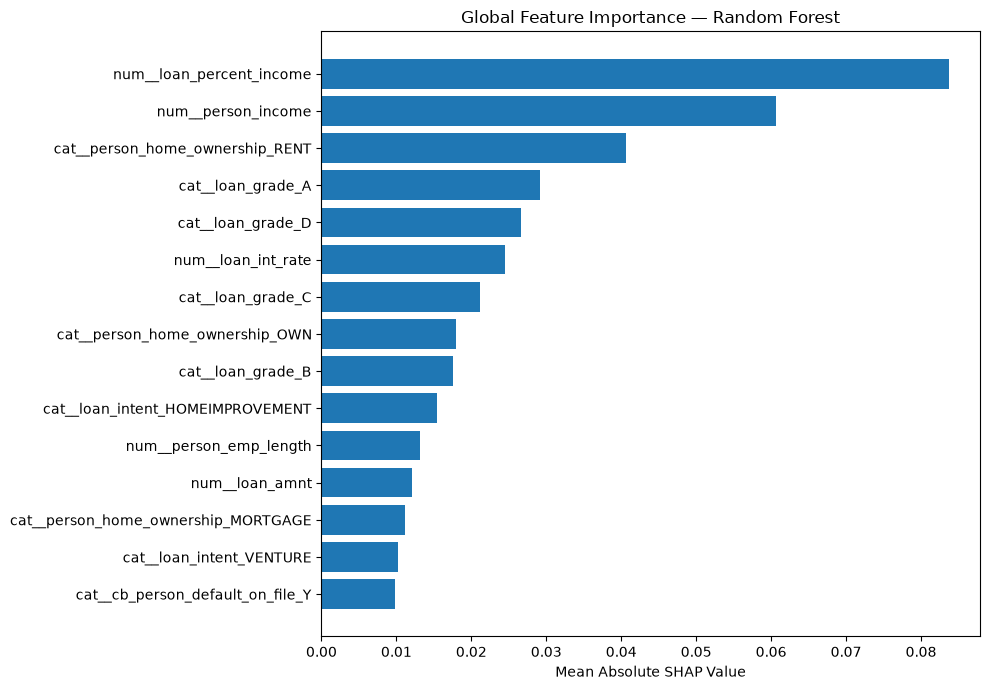

In [32]:

# Handle SHAP output formats across versions
if isinstance(shap_values, list):
    # Older SHAP versions: one array per class
    shap_default = shap_values[1]
elif getattr(shap_values, "ndim", 0) == 3:
    # Newer versions: samples x features x classes
    shap_default = shap_values[:, :, 1]
else:
    shap_default = shap_values

# Global importance: mean absolute SHAP value
mean_abs_shap = np.abs(shap_default).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_abs_shap
}).sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

display(shap_importance.head(15).round(4))

# Plot the top 15 features
top_features = shap_importance.head(15).sort_values(
    "Mean Absolute SHAP"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Mean Absolute SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.title("Global Feature Importance — Random Forest")
plt.tight_layout()
plt.show()


Predicted default probability: 0.0075


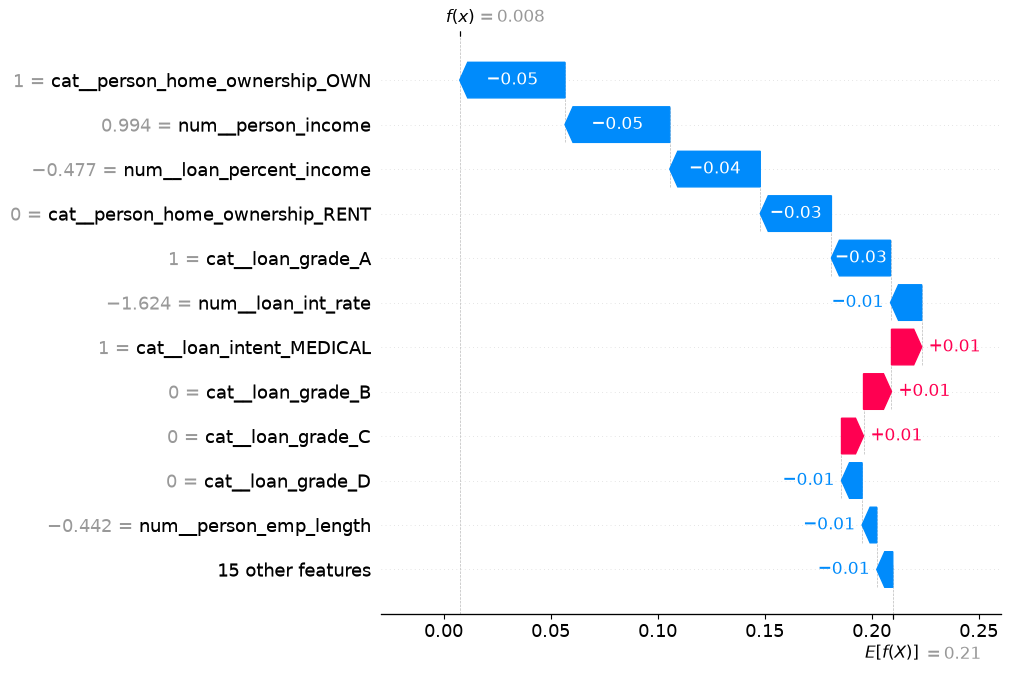

In [33]:

# Explain the first applicant in our SHAP sample
applicant_index = 0

applicant_transformed = X_explain_transformed[
    applicant_index:applicant_index + 1
]

applicant_probability = rf_model.predict_proba(
    X_shap_explain.iloc[[applicant_index]]
)[0, 1]

print("Predicted default probability:", round(
    float(applicant_probability), 4
))

# Create an explanation for the default class
base_value = tree_explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).reshape(-1)[-1]

shap_explanation = shap.Explanation(
    values=shap_default[applicant_index],
    base_values=float(base_value),
    data=applicant_transformed[0],
    feature_names=feature_names
)

shap.plots.waterfall(shap_explanation, max_display=12)


In [34]:
# ============================================
# PHASE 7: THRESHOLD SELECTION
# Using calibrated validation probabilities
# ============================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results_calibrated = []

for threshold in np.arange(0.20, 0.61, 0.05):

    predictions = (
        calibrated_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results_calibrated.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

calibrated_threshold_df = pd.DataFrame(
    threshold_results_calibrated
)

display(calibrated_threshold_df.round(4))


,threshold,precision,recall,f1_score,false_positives,false_negatives
0,0.20,0.7712,0.7770,0.7741,245,237
1,0.25,0.8332,0.7563,0.7929,161,259
2,0.30,0.8797,0.7498,0.8095,109,266
3,0.35,0.9049,0.7432,0.8161,83,273
4,0.40,0.9240,0.7319,0.8168,64,285
5,0.45,0.9404,0.7272,0.8202,49,290
6,0.50,0.9468,0.7197,0.8177,43,298
7,0.55,0.9609,0.7168,0.8211,31,301
8,0.60,0.9655,0.7112,0.8191,27,307


FINAL TEST SET RESULTS
ROC-AUC: 0.9388
PR-AUC: 0.8939
Brier Score: 0.0552
Log Loss: 0.2037

Decision threshold: 0.55

Classification Report:
                 precision    recall  f1-score   support

Non-default (0)       0.93      0.99      0.96      3799
    Default (1)       0.95      0.73      0.83      1064

       accuracy                           0.93      4863
      macro avg       0.94      0.86      0.89      4863
   weighted avg       0.94      0.93      0.93      4863


Confusion Matrix:


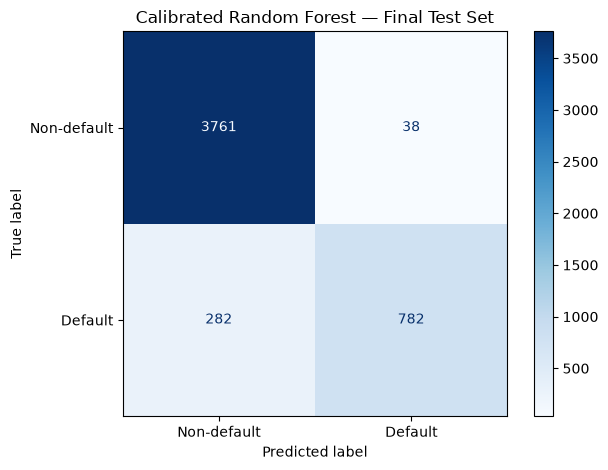

In [35]:
# ============================================
# PHASE 8: FINAL TEST SET EVALUATION
# ============================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Threshold selected using validation results only
FINAL_THRESHOLD = 0.55

# Generate probabilities on the untouched test set
test_probabilities = calibrated_rf.predict_proba(X_test)[:, 1]

# Convert probabilities into binary predictions
test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

# Calculate final test metrics
test_metrics = {
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities),
    "Brier Score": brier_score_loss(y_test, test_probabilities),
    "Log Loss": log_loss(y_test, test_probabilities)
}

print("FINAL TEST SET RESULTS")
print("=" * 45)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print(f"\nDecision threshold: {FINAL_THRESHOLD}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Non-default (0)", "Default (1)"],
    zero_division=0
))

print("\nConfusion Matrix:")
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Non-default", "Default"],
    cmap="Blues"
)

plt.title("Calibrated Random Forest — Final Test Set")
plt.tight_layout()
plt.show()


In [36]:
# ============================================
# SAVE TRAINED MODEL FOR FASTAPI
# ============================================

from pathlib import Path
import json
import joblib

# Locate the project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Check that the trained model is available
if "calibrated_rf" not in globals():
    raise NameError(
        "calibrated_rf not found. Run the calibration training cell first."
    )

# Save the complete calibrated pipeline
model_path = ARTIFACT_DIR / "credit_risk_model.joblib"
joblib.dump(calibrated_rf, model_path)

# Save model metadata
metadata = {
    "model_name": "Calibrated Random Forest",
    "target_column": "loan_status",
    "positive_class": 1,
    "decision_threshold": 0.55,
    "calibration_method": "sigmoid"
}

if "test_metrics" in globals():
    metadata["test_metrics"] = {
        key: float(value)
        for key, value in test_metrics.items()
    }

metadata_path = ARTIFACT_DIR / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Model saved:", model_path.resolve())
print("Metadata saved:", metadata_path.resolve())

# Verify that the model can be reloaded
loaded_model = joblib.load(model_path)

print("Reload verification: SUCCESS")
print("Artifacts:", [p.name for p in ARTIFACT_DIR.iterdir()])


Model saved: D:\DOWNLOAD\Credit-Risk-ML-System\artifacts\credit_risk_model.joblib
Metadata saved: D:\DOWNLOAD\Credit-Risk-ML-System\artifacts\model_metadata.json
Reload verification: SUCCESS
Artifacts: ['credit_risk_model.joblib', 'model_metadata.json']
